# 03 Classification

## 3.2. Data Preparation

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(data)
df.T

,0,1,2,3,4,5,6,7,8,9,...,7033,7034,7035,7036,7037,7038,7039,7040,7041,7042
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU,9305-CDSKC,1452-KIOVK,6713-OKOMC,7892-POOKP,6388-TABGU,...,9767-FFLEM,0639-TSIQW,8456-QDAVC,7750-EYXWZ,2569-WGERO,6840-RESVB,2234-XADUH,4801-JZAZL,8361-LTMKD,3186-AJIEK
gender,Female,Male,Male,Male,Female,Female,Male,Female,Female,Male,...,Male,Female,Male,Female,Female,Male,Female,Female,Male,Male
SeniorCitizen,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
Partner,Yes,No,No,No,No,No,No,No,Yes,No,...,No,No,No,No,No,Yes,Yes,Yes,Yes,No
Dependents,No,No,No,No,No,No,Yes,No,No,Yes,...,No,No,No,No,No,Yes,Yes,Yes,No,No
tenure,1,34,2,45,2,8,22,10,28,62,...,38,67,19,12,72,24,72,11,4,66
PhoneService,No,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Yes,...,Yes,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Yes
MultipleLines,No phone service,No,No,No phone service,No,Yes,Yes,No phone service,Yes,No,...,No,Yes,No,No phone service,No,Yes,Yes,No phone service,Yes,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic,Fiber optic,Fiber optic,DSL,Fiber optic,DSL,...,Fiber optic,Fiber optic,Fiber optic,DSL,No,DSL,Fiber optic,DSL,Fiber optic,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No,No,No,Yes,No,Yes,...,No,Yes,No,No,No internet service,Yes,No,Yes,No,Yes


In [3]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [4]:
def to_snake_case(col: str) -> str:
    col = list(col.strip().replace(" ", "_"))
    indexes = []

    for i in range(len(col)):
        if i > 0 and col[i].isupper():
            indexes.append(i)

    for i, ind in enumerate(indexes):
        col.insert(ind + i, "_")

    return "".join(col).lower()

In [5]:
to_snake_case("funcTionEtc")

'func_tion_etc'

In [6]:
df.columns = df.rename(
    columns={"customerID": "customer_id", "StreamingTV": "streaming_tv"}
).columns
df.columns = [to_snake_case(col) for col in df.columns]
df.head().T

,0,1,2,3,4
customer_id,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
senior_citizen,0,0,0,0,0
partner,Yes,No,No,No,No
dependents,No,No,No,No,No
tenure,1,34,2,45,2
phone_service,No,Yes,Yes,No,Yes
multiple_lines,No phone service,No,No,No phone service,No
internet_service,DSL,DSL,DSL,DSL,Fiber optic
online_security,No,Yes,Yes,Yes,No


In [7]:
df.dtypes

customer_id              str
gender                   str
senior_citizen         int64
partner                  str
dependents               str
tenure                 int64
phone_service            str
multiple_lines           str
internet_service         str
online_security          str
online_backup            str
device_protection        str
tech_support             str
streaming_tv             str
streaming_movies         str
contract                 str
paperless_billing        str
payment_method           str
monthly_charges      float64
total_charges            str
churn                    str
dtype: object

In [8]:
df[["total_charges", "customer_id"]]

,total_charges,customer_id
0,29.85,7590-VHVEG
1,1889.5,5575-GNVDE
2,108.15,3668-QPYBK
3,1840.75,7795-CFOCW
4,151.65,9237-HQITU
...,...,...
7038,1990.5,6840-RESVB
7039,7362.9,2234-XADUH
7040,346.45,4801-JZAZL
7041,306.6,8361-LTMKD


In [9]:
total_ch = pd.to_numeric(df.total_charges, errors="coerce")
total_ch

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: total_charges, Length: 7043, dtype: float64

In [10]:
total_ch.isnull().sum()

np.int64(11)

In [11]:
df.total_charges = pd.to_numeric(df.total_charges, errors="coerce").fillna(0)
df[df.total_charges.isnull()]

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn


In [12]:
df.churn

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: churn, Length: 7043, dtype: str

In [13]:
df.churn = (df.churn == "Yes").astype(int)

In [14]:
df.head().T

,0,1,2,3,4
customer_id,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
senior_citizen,0,0,0,0,0
partner,Yes,No,No,No,No
dependents,No,No,No,No,No
tenure,1,34,2,45,2
phone_service,No,Yes,Yes,No,Yes
multiple_lines,No phone service,No,No,No phone service,No
internet_service,DSL,DSL,DSL,DSL,Fiber optic
online_security,No,Yes,Yes,Yes,No


## 3.3 Setting Up The Validation Framework

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
train_test_split?

Signature:
train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
)
Docstring:
Split arrays or matrices into random train and test subsets.

Quick utility that wraps input validation,
``next(ShuffleSplit().split(X, y))``, and application to input data
into a single call for splitting (and optionally subsampling) data into a
one-liner.

Read more in the :ref:`User Guide <cross_validation>`.

Parameters
----------
*arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
    Indexable data-structures can be arrays, lists, dataframes, scipy
    sparse matrices or pandas dataframes with consistent first dimension.

test_size : float or int, default=None
    If float, should be between 0.0 and 1.0 and represent the proportion
    of the dataset to include in the test split. If int, represents the
    absolute number of test samples. If None, the value is set to the
    complement 

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
len(df_full_train), len(df_test)

(5634, 1409)

In [18]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df_train), len(df_val)

(4225, 1409)

In [19]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [21]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [22]:
del df_train["churn"]
del df_val["churn"]
del df_test["churn"]

## 3.4 EDA

In [23]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,5442-PPTJY,Male,0,Yes,Yes,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.70,258.35,0
1,6261-RCVNS,Female,0,No,No,42,Yes,No,DSL,Yes,...,Yes,Yes,No,Yes,One year,No,Credit card (automatic),73.90,3160.55,1
2,2176-OSJUV,Male,0,Yes,No,71,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),65.15,4681.75,0
3,6161-ERDGD,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,No,Electronic check,85.45,6300.85,0
4,2364-UFROM,Male,0,No,No,30,Yes,No,DSL,Yes,...,No,Yes,Yes,No,One year,No,Electronic check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781-LKXBR,Male,1,No,No,9,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.50,918.60,1
5630,3507-GASNP,Male,0,No,Yes,60,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.95,1189.90,0
5631,8868-WOZGU,Male,0,No,No,28,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.70,2979.50,1
5632,1251-KRREG,Male,0,No,No,2,Yes,Yes,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,54.40,114.10,1


In [24]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [25]:
df_full_train.churn.mean()

np.float64(0.26996805111821087)

In [26]:
global_churn_rate = df_full_train.churn.mean()
round(global_churn_rate, 2)

np.float64(0.27)

In [27]:
numerical = list(
    df_full_train.dtypes[
        (df_full_train.dtypes == "int64") | (df_full_train.dtypes == "float64")
    ].index[1:-1]
)
numerical

['tenure', 'monthly_charges', 'total_charges']

In [28]:
categorical = [
    "gender",
    "senior_citizen",
    "partner",
    "dependents",
    "phone_service",
    "multiple_lines",
    "internet_service",
    "online_security",
    "online_backup",
    "device_protection",
    "tech_support",
    "streaming_tv",
    "streaming_movies",
    "contract",
    "paperless_billing",
    "payment_method",
]
categorical

['gender',
 'senior_citizen',
 'partner',
 'dependents',
 'phone_service',
 'multiple_lines',
 'internet_service',
 'online_security',
 'online_backup',
 'device_protection',
 'tech_support',
 'streaming_tv',
 'streaming_movies',
 'contract',
 'paperless_billing',
 'payment_method']

In [29]:
df_full_train[categorical].nunique()

gender               2
senior_citizen       2
partner              2
dependents           2
phone_service        2
multiple_lines       3
internet_service     3
online_security      3
online_backup        3
device_protection    3
tech_support         3
streaming_tv         3
streaming_movies     3
contract             3
paperless_billing    2
payment_method       4
dtype: int64

## 3.5 Feature Importance: Churn Rate And Risk Ratio

In [30]:
churn_female = df_full_train[df_full_train.gender == "Female"].churn.mean()
churn_male = df_full_train[df_full_train.gender == "Male"].churn.mean()
print(
    f"Churn male: {churn_male}",
    f"Churn Female: {churn_female}",
    f"Global Churn: {global_churn_rate}",
    sep="\n",
)

Churn male: 0.2632135306553911
Churn Female: 0.27682403433476394
Global Churn: 0.26996805111821087


In [31]:
df_full_train.partner.value_counts()

partner
No     2932
Yes    2702
Name: count, dtype: int64

In [32]:
churn_partner = df_full_train[df_full_train.partner == "Yes"].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == "No"].churn.mean()
print(
    f"Churn with partner: {churn_partner}",
    f"Churn without partner: {churn_no_partner}",
    sep="\n",
)

Churn with partner: 0.20503330866025166
Churn without partner: 0.3298090040927694


In [33]:
global_churn_rate - churn_partner

np.float64(0.06493474245795922)

In [34]:
global_churn_rate - churn_no_partner

np.float64(-0.05984095297455855)

In [35]:
churn_no_partner / global_churn_rate

np.float64(1.2216593879412643)

In [36]:
churn_partner / global_churn_rate

np.float64(0.7594724924338315)

In SQL:

```sql
SELECT
    gender,
    AVG(churn),
    AVG(churn) - global_churn AS diff,
    AVG(churn) / global_churn AS risk
FROM
    data
GROUP BY
    gender;
```

In Pandas:

In [37]:
from IPython.display import display

In [38]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(["mean", "count"])
    df_group["diff"] = df_group["mean"] - global_churn_rate
    df_group["risk"] = df_group["mean"] / global_churn_rate
    display(df_group)

gender


,mean,count,diff,risk
gender,,,,
Female,0.276824,2796,0.006856,1.025396
Male,0.263214,2838,-0.006755,0.974980


senior_citizen


,mean,count,diff,risk
senior_citizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208


partner


,mean,count,diff,risk
partner,,,,
No,0.329809,2932,0.059841,1.221659
Yes,0.205033,2702,-0.064935,0.759472


dependents


,mean,count,diff,risk
dependents,,,,
No,0.313760,3968,0.043792,1.162212
Yes,0.165666,1666,-0.104302,0.613651


phone_service


,mean,count,diff,risk
phone_service,,,,
No,0.241316,547,-0.028652,0.893870
Yes,0.273049,5087,0.003081,1.011412


multiple_lines


,mean,count,diff,risk
multiple_lines,,,,
No,0.257407,2700,-0.012561,0.953474
No phone service,0.241316,547,-0.028652,0.893870
Yes,0.290742,2387,0.020773,1.076948


internet_service


,mean,count,diff,risk
internet_service,,,,
DSL,0.192347,1934,-0.077621,0.712482
Fiber optic,0.425171,2479,0.155203,1.574895
No,0.077805,1221,-0.192163,0.288201


online_security


,mean,count,diff,risk
online_security,,,,
No,0.420921,2801,0.150953,1.559152
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.153226,1612,-0.116742,0.567570


online_backup


,mean,count,diff,risk
online_backup,,,,
No,0.404323,2498,0.134355,1.497672
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.217232,1915,-0.052736,0.804660


device_protection


,mean,count,diff,risk
device_protection,,,,
No,0.395875,2473,0.125907,1.466379
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.230412,1940,-0.039556,0.853480


tech_support


,mean,count,diff,risk
tech_support,,,,
No,0.418914,2781,0.148946,1.551717
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.159926,1632,-0.110042,0.592390


streaming_tv


,mean,count,diff,risk
streaming_tv,,,,
No,0.342832,2246,0.072864,1.269897
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.302723,2167,0.032755,1.121328


streaming_movies


,mean,count,diff,risk
streaming_movies,,,,
No,0.338906,2213,0.068938,1.255358
No internet service,0.077805,1221,-0.192163,0.288201
Yes,0.307273,2200,0.037305,1.138182


contract


,mean,count,diff,risk
contract,,,,
Month-to-month,0.431701,3104,0.161733,1.599082
One year,0.120573,1186,-0.149395,0.446621
Two year,0.028274,1344,-0.241694,0.104730


paperless_billing


,mean,count,diff,risk
paperless_billing,,,,
No,0.172071,2313,-0.097897,0.637375
Yes,0.338151,3321,0.068183,1.252560


payment_method


,mean,count,diff,risk
payment_method,,,,
Bank transfer (automatic),0.168171,1219,-0.101797,0.622928
Credit card (automatic),0.164339,1217,-0.105630,0.608733
Electronic check,0.455890,1893,0.185922,1.688682
Mailed check,0.193870,1305,-0.076098,0.718121


## 3.6 Feature Importance: Mutual Information

In [39]:
from sklearn.metrics import mutual_info_score

In [40]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [41]:
mi = df_full_train[categorical].apply(
    lambda s: mutual_info_score(s, df_full_train.churn)
)
mi.sort_values(ascending=False)

contract             0.098320
online_security      0.063085
tech_support         0.061032
internet_service     0.055868
online_backup        0.046923
device_protection    0.043453
payment_method       0.043210
streaming_tv         0.031853
streaming_movies     0.031581
paperless_billing    0.017589
dependents           0.012346
partner              0.009968
senior_citizen       0.009410
multiple_lines       0.000857
phone_service        0.000229
gender               0.000117
dtype: float64

## 3.7 Feature Importance: Correlation

In [42]:
df_full_train.tenure.min(), df_full_train.tenure.max()

(np.int64(0), np.int64(72))

In [43]:
display(
    df_full_train[numerical].head(),
    df_full_train[numerical].corrwith(df_full_train.churn),
)

,tenure,monthly_charges,total_charges
0,12,19.70,258.35
1,42,73.90,3160.55
2,71,65.15,4681.75
3,71,85.45,6300.85
4,30,70.40,2044.75


tenure            -0.351885
monthly_charges    0.196805
total_charges     -0.196353
dtype: float64

In [44]:
print(
    f"Tenure (0, 2] months: {df_full_train[df_full_train.tenure <= 2].churn.mean()}",
    f"Tenure (2, 12] months: {df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()}",
    f"Tenure (12, +) months: {df_full_train[df_full_train.tenure > 12].churn.mean()}",
    sep="\n",
)

Tenure (0, 2] months: 0.5953420669577875
Tenure (2, 12] months: 0.3994413407821229
Tenure (12, +) months: 0.17634908339788277


In [45]:
print(
    f"Monthly charges (0, 20] dollars: {df_full_train[df_full_train.monthly_charges <= 20].churn.mean()}",
    f"Monthly charges (20, 50] dollars: {df_full_train[(df_full_train.monthly_charges > 20) & (df_full_train.monthly_charges <= 50)].churn.mean()}",
    f"Monthly charges (50, +) dollars: {df_full_train[df_full_train.monthly_charges > 50].churn.mean()}",
    sep="\n",
)

Monthly charges (0, 20] dollars: 0.08795411089866156
Monthly charges (20, 50] dollars: 0.18340943683409436
Monthly charges (50, +) dollars: 0.32499341585462205


In [46]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure             0.351885
monthly_charges    0.196805
total_charges      0.196353
dtype: float64

## 3.8 One-Hot Encoding

In [47]:
from sklearn.feature_extraction import DictVectorizer

In [48]:
df_train[["gender", "contract"]][:100]

,gender,contract
0,Female,Two year
1,Male,Month-to-month
2,Female,Month-to-month
3,Female,Month-to-month
4,Female,Two year
...,...,...
95,Male,One year
96,Female,Month-to-month
97,Male,Month-to-month
98,Male,One year


In [49]:
dicts = df_train[["gender", "contract"]][:100].to_dict(orient="records")
dicts

[{'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Male', 'contract': 'Month-to-month'},
 {'gender': 'Female', 'contract': 'Two year'},
 {'gender': 'Female', 'contract': 'Month-to-month'},
 {'gender': 'Male', 'contract': 'One year'},
 {'gender': 'Male', 'contract': 'Two year'},
 {

In [50]:
dv = DictVectorizer(sparse=False)
dv.fit(dicts)

DictVectorizer(sparse=False)

In [51]:
dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'gender=Female', 'gender=Male'], dtype=object)

In [52]:
dv.transform(dicts)

array([[0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 1., 0., 0., 1.],
       [0., 0., 1., 0., 1.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 0., 1., 1., 0.],
       [1., 0., 0., 0., 1.],
       [0., 0., 1., 0., 1.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0.],
       [0., 1., 0., 1., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       [0., 1., 0., 1., 0.],
       [0., 1., 0., 1., 0.],
       [1., 0.

In [53]:
train_dicts = df_train[categorical + numerical].to_dict(orient="records")
train_dicts[0]

{'gender': 'Female',
 'senior_citizen': 0,
 'partner': 'Yes',
 'dependents': 'Yes',
 'phone_service': 'Yes',
 'multiple_lines': 'Yes',
 'internet_service': 'Fiber optic',
 'online_security': 'Yes',
 'online_backup': 'Yes',
 'device_protection': 'Yes',
 'tech_support': 'Yes',
 'streaming_tv': 'Yes',
 'streaming_movies': 'Yes',
 'contract': 'Two year',
 'paperless_billing': 'Yes',
 'payment_method': 'Electronic check',
 'tenure': 72,
 'monthly_charges': 115.5,
 'total_charges': 8425.15}

In [54]:
dv = DictVectorizer(sparse=False)
dv.fit(dicts)

DictVectorizer(sparse=False)

In [55]:
dv.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'gender=Female', 'gender=Male'], dtype=object)

In [56]:
list(dv.transform(train_dicts)[0])

[np.float64(0.0),
 np.float64(0.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(0.0)]

In [57]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_train

array([[0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.20000e+01, 8.42515e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.00000e+01, 1.02155e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        5.00000e+00, 4.13650e+02],
       ...,
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        2.00000e+00, 1.90050e+02],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        2.70000e+01, 7.61950e+02],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        9.00000e+00, 7.51650e+02]], shape=(4225, 45))

In [58]:
val_dicts = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dicts)
X_val

array([[0.0000e+00, 0.0000e+00, 1.0000e+00, ..., 1.0000e+00, 7.1000e+01,
        4.9734e+03],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        2.0750e+01],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        2.0350e+01],
       ...,
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 1.0000e+00, 1.8000e+01,
        1.0581e+03],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        9.3300e+01],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 3.0000e+00,
        2.9285e+02]], shape=(1409, 45))

## 

## 3.9 Logistic Regression

In [59]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [60]:
z = np.linspace(-5, 5, 51)
z

array([-5. , -4.8, -4.6, -4.4, -4.2, -4. , -3.8, -3.6, -3.4, -3.2, -3. ,
       -2.8, -2.6, -2.4, -2.2, -2. , -1.8, -1.6, -1.4, -1.2, -1. , -0.8,
       -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2,  1.4,
        1.6,  1.8,  2. ,  2.2,  2.4,  2.6,  2.8,  3. ,  3.2,  3.4,  3.6,
        3.8,  4. ,  4.2,  4.4,  4.6,  4.8,  5. ])

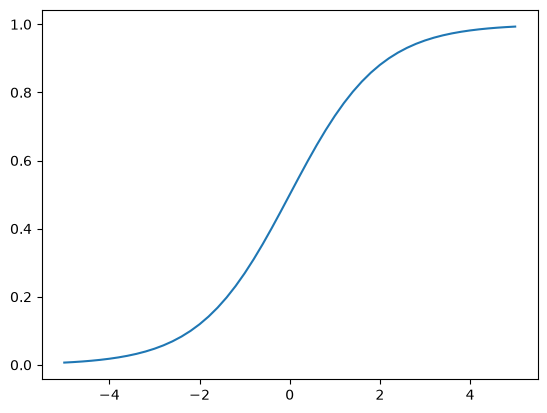

In [61]:
plt.plot(z, sigmoid(z))

## 3.10 Training Logistic Regression with Scikit-Learn

In [62]:
from sklearn.linear_model import LogisticRegression

In [63]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [64]:
model.coef_[0]

array([ 6.82927854e-01,  3.45081586e-02, -6.76268731e-01,  5.60639878e-02,
       -1.48967048e-02,  1.13757561e-01, -1.60009142e-01,  8.74188645e-02,
        3.96519760e-02,  1.51530728e-03, -4.98397338e-01,  6.99573763e-01,
       -1.60009142e-01, -1.79735066e-02, -1.87550163e-01,  6.71246735e-02,
        1.61592773e-01,  1.16827974e-01, -1.60009142e-01,  8.43484505e-02,
        2.85295674e-01, -1.60009142e-01, -8.41192497e-02, -1.61435446e-01,
        2.02602729e-01, -4.41442379e-02,  8.53115211e-02, -5.19702994e-02,
       -2.40617426e-03,  1.06260138e-01, -1.07163815e-02,  6.71246735e-02,
       -2.59573903e-02,  1.94664565e-01, -9.46808903e-02, -1.60009142e-01,
        2.95857315e-01, -5.44382596e-02, -1.60009142e-01,  2.55614684e-01,
        2.35014311e-01, -1.60009142e-01, -3.38378864e-02, -6.84266446e-02,
        3.94331896e-04])

In [65]:
model.intercept_[0]

np.float64(-0.04511031924163083)

In [66]:
model.predict(X_train)

array([0, 1, 1, ..., 1, 0, 1], shape=(4225,))

In [67]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_desicion = y_pred >= 0.5

In [68]:
df_val[churn_desicion].customer_id

3       8433-WXGNA
8       3440-JPSCL
12      7228-OMTPN
19      6711-FLDFB
24      2612-RANWT
           ...    
1397    5976-JCJRH
1398    2034-CGRHZ
1399    5276-KQWHG
1407    6521-YYTYI
1408    3049-SOLAY
Name: customer_id, Length: 315, dtype: str

In [69]:
(y_val == churn_desicion.astype(int)).mean()

np.float64(0.8034066713981547)

In [70]:
df_pred = pd.DataFrame()
df_pred["probability"] = y_pred
df_pred["prediction"] = churn_desicion.astype(int)
df_pred["actual"] = y_val
df_pred["correct"] = df_pred["prediction"] == df_pred["actual"]

In [71]:
df_pred.correct.mean()

np.float64(0.8034066713981547)

## 3.11 Model Interpretation

In [72]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=Month-to-month': np.float64(0.683),
 'contract=One year': np.float64(0.035),
 'contract=Two year': np.float64(-0.676),
 'dependents=No': np.float64(0.056),
 'dependents=Yes': np.float64(-0.015),
 'device_protection=No': np.float64(0.114),
 'device_protection=No internet service': np.float64(-0.16),
 'device_protection=Yes': np.float64(0.087),
 'gender=Female': np.float64(0.04),
 'gender=Male': np.float64(0.002),
 'internet_service=DSL': np.float64(-0.498),
 'internet_service=Fiber optic': np.float64(0.7),
 'internet_service=No': np.float64(-0.16),
 'monthly_charges': np.float64(-0.018),
 'multiple_lines=No': np.float64(-0.188),
 'multiple_lines=No phone service': np.float64(0.067),
 'multiple_lines=Yes': np.float64(0.162),
 'online_backup=No': np.float64(0.117),
 'online_backup=No internet service': np.float64(-0.16),
 'online_backup=Yes': np.float64(0.084),
 'online_security=No': np.float64(0.285),
 'online_security=No internet service': np.float64(-0.16),
 'online_security

In [73]:
small = ["contract", "tenure", "monthly_charges"]
dicts_train_small = df_train[small].to_dict(orient="records")
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [74]:
X_train_small = dv_small.transform(dicts_train_small)
X_train_small

array([[  0.  ,   0.  ,   1.  , 115.5 ,  72.  ],
       [  1.  ,   0.  ,   0.  ,  95.25,  10.  ],
       [  1.  ,   0.  ,   0.  ,  75.55,   5.  ],
       ...,
       [  1.  ,   0.  ,   0.  ,  90.  ,   2.  ],
       [  0.  ,   0.  ,   1.  ,  24.5 ,  27.  ],
       [  1.  ,   0.  ,   0.  ,  80.85,   9.  ]], shape=(4225, 5))

In [75]:
dv_small.get_feature_names_out()

array(['contract=Month-to-month', 'contract=One year',
       'contract=Two year', 'monthly_charges', 'tenure'], dtype=object)

In [76]:
model_small = LogisticRegression()
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [77]:
model_small.intercept_[0]

np.float64(-2.477957596118287)

In [78]:
model_small.coef_[0]

array([ 0.9711394 , -0.02379507, -0.94828863,  0.02748534, -0.03619005])

In [79]:
dict(zip(dv_small.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=Month-to-month': np.float64(0.683),
 'contract=One year': np.float64(0.035),
 'contract=Two year': np.float64(-0.676),
 'monthly_charges': np.float64(0.056),
 'tenure': np.float64(-0.015)}

In [80]:
-2.47 + 0.97 + 50 * 0.027 + 5 * (-0.036)

-0.3300000000000001

In [81]:
sigmoid(_)

np.float64(0.41824062315816374)

## 3.12 Using the Model

In [84]:
df_full_train_dicts = df_full_train[categorical + numerical].to_dict(orient="records")
df_full_train_dicts

[{'gender': 'Male',
  'senior_citizen': 0,
  'partner': 'Yes',
  'dependents': 'Yes',
  'phone_service': 'Yes',
  'multiple_lines': 'No',
  'internet_service': 'No',
  'online_security': 'No internet service',
  'online_backup': 'No internet service',
  'device_protection': 'No internet service',
  'tech_support': 'No internet service',
  'streaming_tv': 'No internet service',
  'streaming_movies': 'No internet service',
  'contract': 'Two year',
  'paperless_billing': 'No',
  'payment_method': 'Mailed check',
  'tenure': 12,
  'monthly_charges': 19.7,
  'total_charges': 258.35},
 {'gender': 'Female',
  'senior_citizen': 0,
  'partner': 'No',
  'dependents': 'No',
  'phone_service': 'Yes',
  'multiple_lines': 'No',
  'internet_service': 'DSL',
  'online_security': 'Yes',
  'online_backup': 'Yes',
  'device_protection': 'Yes',
  'tech_support': 'Yes',
  'streaming_tv': 'No',
  'streaming_movies': 'Yes',
  'contract': 'One year',
  'paperless_billing': 'No',
  'payment_method': 'Credit c

In [88]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(df_full_train_dicts)
X_full_train

array([[0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 2.58350e+02],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        4.20000e+01, 3.16055e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.10000e+01, 4.68175e+03],
       ...,
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.80000e+01, 2.97950e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.00000e+00, 1.14100e+02],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        1.60000e+01, 1.11485e+03]], shape=(5634, 45))

In [89]:
y_full_train = df_full_train.churn.values
y_full_train

array([0, 1, 0, ..., 1, 1, 0], shape=(5634,))

In [116]:
model = LogisticRegression(max_iter=10000).fit(X_full_train, y_full_train)
model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [117]:
dicts_test = df_test[categorical + numerical].to_dict(orient="records")
X_test = dv.transform(dicts_test)
X_test

array([[0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        4.10000e+01, 3.32075e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        6.60000e+01, 6.47185e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 5.24350e+02],
       ...,
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.10000e+01, 3.88865e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        6.50000e+01, 5.68845e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.70000e+01, 1.74350e+03]], shape=(1409, 45))

In [118]:
y_pred = model.predict_proba(X_test)[:, 1]
churn_desicion = y_pred >= 0.5
(churn_desicion == y_test).mean()

np.float64(0.8112136266855926)

In [119]:
pick = -1
X_small = dv.transform(dicts_test[pick])
(model.predict_proba(X_small)[:, 1] >= 0.5).astype(int), y_test[pick]

(array([1]), np.int64(1))